# Fase 2 · Hotel Booking Demand | Entrega auditada para Google Colab

**Universidad de La Salle · Maestría en Inteligencia Artificial · Ciencia de Datos**

**Integrantes**· Carlos Arnulfo Cogua Laverde, Michael Lan Alvarez

**Objetivo:** cumplir la sección 3.2 de la guía: limpieza e imputación, estudio de extremos, **dos variables derivadas**, codificación/escalamiento ajustados solo en entrenamiento, partición **train/validation/test**, análisis de desbalance y modelos **baseline**.

- **Fuente:** [Hotel Booking Demand, Kaggle (Jesse Mostipak)](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand). Dataset original procedente de António, de Almeida y Nunes (2019), DOI [10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). Atribuir la fuente y verificar su licencia de redistribución antes de publicar los datos.

- **Tecnologías:** Polars, NumPy, SciPy/scikit-learn, Matplotlib y KaggleHub; **no se usa Pandas**.



## 1. Inicio

In [1]:
# Instalar paquetes del proyecto sin modificar el kernel administrado por Google Colab.
# Si ya están disponibles, en un entorno local puede omitir esta celda.
# Si Colab solicita reiniciar la sesión tras instalar, reiníciela y ejecute desde arriba.
%pip install -q "polars==1.35.2" "numpy==2.2.6" "scipy==1.16.2" "scikit-learn==1.7.2" "matplotlib==3.10.3" "kagglehub==0.3.13"


In [2]:
import csv
import hashlib
import json
import math
import shutil
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if sys.version_info < (3, 12):
    raise RuntimeError("Este notebook requiere Python 3.12 o superior")

SEED = 42
root = Path("/content") if "google.colab" in sys.modules else Path.cwd()
if (root / "preprocesamiento").is_dir():
    root = root / "preprocesamiento"
raw_dir = root / "data/raw"
output_dir = root / "outputs/notebook_phase2"
processed_dir = root / "data/processed/notebook_phase2"
if (
    output_dir.resolve() == (root / "outputs").resolve()
    or processed_dir.resolve() == (root / "data/processed").resolve()
):
    raise ValueError("Use separate notebook destinations, not canonical directories")
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(9)
pl.Config.set_fmt_str_lengths(32)
print(f"Python real: {sys.version.split()[0]} · seed={SEED}")
print("Entorno Google Colab:", "google.colab" in sys.modules)
print("Dependencias:", {name: version(name) for name in ["polars", "numpy", "scipy", "scikit-learn", "matplotlib", "kagglehub"]})

Python real: 3.13.18 · seed=42
Entorno Google Colab: True
Dependencias: {'polars': '1.35.2', 'numpy': '2.2.6', 'scipy': '1.16.2', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.3', 'kagglehub': '0.3.13'}


## 2. Fuente, carga y validación

Fuente: [Kaggle, Jesse Mostipak](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand), a partir de António, de Almeida y Nunes (2019), [DOI 10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). Licencia **CC BY 4.0**: conservar atribución.

El CSV público combinado tiene **119390 × 32**. `agent` y `company` son identificadores nominales, no magnitudes. Validamos nombres/tipos y target binario. La función lectora admite fixtures pequeños; la adquisición real exige las dimensiones públicas. Si el CSV ya existe, **no se descarga ni reescribe**; si falta, Kagglehub obtiene el original. Un error no se reemplaza con datos ficticios. Se registra inspección local/hash, nunca una fecha de descarga no acreditada.
**Compatibilidad del CSV:** la cabecera se lee con `csv.reader` (biblioteca estándar) para evitar la inferencia de tipos en la inspección inicial. La lectura efectiva utiliza `schema_overrides` (`children` como `Float64`) y declara `NA`, `NULL` y cadenas vacías como valores nulos. No se usa `ignore_errors=True` ni se descartan registros por errores de lectura.


In [3]:
COLUMNS = [
    "hotel",
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "assigned_room_type",
    "booking_changes",
    "deposit_type",
    "agent",
    "company",
    "days_in_waiting_list",
    "customer_type",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "reservation_status",
    "reservation_status_date",
]

CATEGORICAL = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "agent",
    "company",
    "customer_type",
    "reservation_status",
    "is_canceled",
]

STRINGS = set(CATEGORICAL) - {"is_canceled", "is_repeated_guest"} | {
    "reservation_status_date"
}

SCHEMA = {
    name: pl.String
    if name in STRINGS
    else pl.Float64
    if name in {"children", "adr"}
    else pl.Int64
    for name in COLUMNS
}

DATASET = "jessemostipak/hotel-booking-demand"

In [4]:
def read_bookings(path: Path) -> pl.DataFrame:
    "Lee el esquema original de 32 columnas y valida el objetivo binario."
    # Inspección de cabecera sin inferir tipos; `children` contiene NA en el CSV.
    with path.open("r", encoding="utf-8-sig", newline="") as csv_file:
        names = next(csv.reader(csv_file), [])
    if len(names) != len(COLUMNS) or set(names) != set(COLUMNS):
        raise ValueError("Expected 32 columns matching Hotel Booking Demand schema")
    frame = pl.read_csv(
        path,
        schema_overrides=SCHEMA,
        null_values=["NULL", "NA", ""],
        infer_schema_length=10000,
    )
    if frame.is_empty():
        raise ValueError("Dataset must contain bookings")
    if (
        not set(frame["is_canceled"].drop_nulls().unique()) <= {0, 1}
        or frame["is_canceled"].null_count()
    ):
        raise ValueError("is_canceled must contain only 0 and 1")
    return frame.select(COLUMNS)

In [5]:
def write_json(path: Path, data: object) -> None:
    "Escribe JSON legible y convierte valores no finitos a nulos explícitos."

    def sanitize(value):
        """Normaliza recursivamente escalares, listas y diccionarios para JSON."""
        if isinstance(value, dict):
            return {str(key): sanitize(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [sanitize(item) for item in value]
        if isinstance(value, float) and not math.isfinite(value):
            return None
        if hasattr(value, "item"):
            return sanitize(value.item())
        return value

    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(sanitize(data), indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8",
    )


def prepare(raw_dir: Path, output_dir: Path) -> pl.DataFrame:
    "Reutiliza el CSV intacto o lo adquiere con Kagglehub y registra procedencia."
    path = raw_dir / "hotel_bookings.csv"
    source_metadata = output_dir / "source.json"
    prior = (
        json.loads(source_metadata.read_text(encoding="utf-8"))
        if source_metadata.exists()
        else {}
    )
    acquisition = prior.get(
        "acquisition",
        {
            "obtained_at_utc": datetime.now(UTC).isoformat(),
            "origin": "local_cached" if path.exists() else "pending",
            "downloaded_at_utc": None,
            "local_file_modified_at_utc": datetime.fromtimestamp(
                path.stat().st_mtime, UTC
            ).isoformat()
            if path.exists()
            else None,
            "meaning": "Local acquisition/inspection recorded now; original download timestamp was not captured and remains unknown. Filesystem modification is not proof of network download.",
        },
    )
    if not path.exists():
        import kagglehub

        try:
            source = Path(kagglehub.dataset_download(DATASET)) / path.name
            raw_dir.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, path)
            acquisition = {
                "obtained_at_utc": datetime.now(UTC).isoformat(),
                "origin": "kagglehub_cache_or_download",
                "downloaded_at_utc": None,
                "method": "kagglehub.dataset_download (may reuse Kaggle cache), then local original copy",
                "kaggle_cache_version": source.parent.name,
            }
        except Exception as exc:
            raise RuntimeError(f"Kaggle download failed for {DATASET}: {exc}") from exc
    frame = read_bookings(path)
    if frame.shape != (119390, 32):
        raise ValueError(f"Unexpected public dataset dimensions: {frame.shape}")
    write_json(
        output_dir / "source.json",
        {
            "dataset": DATASET,
            "acquisition": acquisition,
            "license": "Revisar licencia oficial publicada por el distribuidor antes de redistribuir el CSV",
            "attribution": "Antonio, de Almeida and Nunes (2019), DOI 10.1016/j.dib.2018.11.126; Kaggle redistributor Jesse Mostipak",
            "kaggle_cache_version": acquisition.get("kaggle_cache_version"),
            "url": f"https://www.kaggle.com/datasets/{DATASET}",
            "verified_at_utc": datetime.now(UTC).isoformat(),
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
            "rows": frame.height,
            "columns": frame.width,
            "schema": {key: str(value) for key, value in frame.schema.items()},
        },
    )
    return frame

In [6]:
raw = prepare(raw_dir, output_dir)
raw_hash = hashlib.sha256((raw_dir / "hotel_bookings.csv").read_bytes()).hexdigest()
print(f"Original: {raw.height} reservas × {raw.width} columnas")
print(f"SHA-256: {raw_hash}")
print(raw.select("hotel", "is_canceled", "adults", "children", "adr").head(5))

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Original: 119390 reservas × 32 columnas
SHA-256: 7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06
shape: (5, 5)
┌──────────────┬─────────────┬────────┬──────────┬──────┐
│ hotel        ┆ is_canceled ┆ adults ┆ children ┆ adr  │
│ ---          ┆ ---         ┆ ---    ┆ ---      ┆ ---  │
│ str          ┆ i64         ┆ i64    ┆ f64      ┆ f64  │
╞══════════════╪═════════════╪════════╪══════════╪══════╡
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 0.0  │
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 0.0  │
│ Resort Hotel ┆ 0           ┆ 1      ┆ 0.0      ┆ 75.0 │
│ Resort Hotel ┆ 0           ┆ 1      ┆ 0.0      ┆ 75.0 │
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 98.0 │
└──────────────┴─────────────┴────────┴──────────┴──────┘


## 3. Diagnóstico de calidad antes de imputar

**MCAR**: ausencia independiente de valores observados/no observados. **MAR**: dependiente de covariables observadas. **MNAR**: depende del propio valor desconocido aun condicionando por las observadas. Las tasas por hotel, cancelación y segmento permiten explorar diferencias; **no prueban ni descartan por sí solas ninguno de los mecanismos**. Los cuatro niños desconocidos del CSV actual se concentran en canceladas del hotel urbano: MAR es plausible, MNAR no se excluye; no afirmamos MCAR demostrado ni rechazo formal.

`agent/company` NULL es **no aplicable** según la fuente, no un número para imputar. Se excluyen del baseline; `country` también por disponibilidad incierta al check-in. Para `children`, mediana de train: robusta y sencilla ante pocos faltantes. Eliminar esas reservas perdería adultos conocidos; KNN/Iterative añadirían supuestos y complejidad sin evidencia de mejora. No se ajusta todavía ninguna imputación.

IQR es una **bandera exploratoria** sobre el original, no un umbral aprendido para filtrar holdouts. Mostramos también repetidos; una fila idéntica puede ser otra reserva real y no se elimina.

In [7]:
def quality_diagnostics(frame: pl.DataFrame) -> dict:
    """Resume ausencia condicionada, repetidos y colas sin modificar las reservas."""
    missing = {
        name: {
            "count": frame[name].null_count(),
            "percent": 100 * frame[name].null_count() / frame.height,
        }
        for name in COLUMNS
    }
    absence = {
        name: {
            group: frame.group_by(group)
            .agg(
                pl.len().alias("rows"),
                pl.col(name).is_null().sum().alias("missing"),
                (100 * pl.col(name).is_null().mean()).alias("missing_percent"),
            )
            .sort(group)
            .to_dicts()
            for group in ["hotel", "is_canceled", "market_segment"]
        }
        for name in COLUMNS
        if missing[name]["count"]
    }
    q1 = frame["adr"].quantile(0.25, interpolation="linear")
    q3 = frame["adr"].quantile(0.75, interpolation="linear")
    assert q1 is not None and q3 is not None
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return {
        "missing": missing,
        "missingness_by_group": absence,
        "duplicates_extra": frame.height - frame.unique().height,
        "duplicate_member_rows": int(frame.is_duplicated().sum()),
        "adr_iqr": {
            "lower": lower,
            "upper": upper,
            "below": frame.filter(pl.col("adr") < lower).height,
            "above": frame.filter(pl.col("adr") > upper).height,
            "zero": frame.filter(pl.col("adr") == 0).height,
        },
    }


quality = quality_diagnostics(raw)
print(
    pl.DataFrame(
        [
            {"variable": name, **item}
            for name, item in quality["missing"].items()
            if item["count"]
        ]
    )
)
print("Ausencia de niños por hotel:")
print(pl.DataFrame(quality["missingness_by_group"]["children"]["hotel"]))
print("Ausencia de niños por cancelación:")
print(pl.DataFrame(quality["missingness_by_group"]["children"]["is_canceled"]))
print(
    {
        key: value
        for key, value in quality.items()
        if key not in {"missing", "missingness_by_group"}
    }
)
write_json(output_dir / "quality.json", quality)

shape: (4, 3)
┌──────────┬────────┬───────────┐
│ variable ┆ count  ┆ percent   │
│ ---      ┆ ---    ┆ ---       │
│ str      ┆ i64    ┆ f64       │
╞══════════╪════════╪═══════════╡
│ children ┆ 4      ┆ 0.00335   │
│ country  ┆ 488    ┆ 0.408744  │
│ agent    ┆ 16340  ┆ 13.686238 │
│ company  ┆ 112593 ┆ 94.306893 │
└──────────┴────────┴───────────┘
Ausencia de niños por hotel:
shape: (2, 4)
┌──────────────┬───────┬─────────┬─────────────────┐
│ hotel        ┆ rows  ┆ missing ┆ missing_percent │
│ ---          ┆ ---   ┆ ---     ┆ ---             │
│ str          ┆ i64   ┆ i64     ┆ f64             │
╞══════════════╪═══════╪═════════╪═════════════════╡
│ City Hotel   ┆ 79330 ┆ 4       ┆ 0.005042        │
│ Resort Hotel ┆ 40060 ┆ 0       ┆ 0.0             │
└──────────────┴───────┴─────────┴─────────────────┘
Ausencia de niños por cancelación:
shape: (2, 4)
┌─────────────┬───────┬─────────┬─────────────────┐
│ is_canceled ┆ rows  ┆ missing ┆ missing_percent │
│ ---         ┆ ---   ┆ --

## 4. Limpieza trazable y tratamiento de extremos

| Regla de dominio | Decisión y motivo |
|---|---|
| ADR negativo o no finito/ausente | Excluir de esta población; no atribuir automáticamente error al original |
| Conteos negativos | Excluir por incoherencia de cantidades |
| Sin huéspedes conocidos o sin noches | Excluir del baseline de estancias con ocupación |
| ADR cero | Conservar: puede representar cortesía |
| Extremo positivo finito | Conservar: puede ser demanda real; IQR no demuestra error |
| Repetidos exactos | Conservar juntos en una partición, no deduplicar |

La remoción razonada se aplica a inválidos de dominio, **no a toda la cola IQR**. Logaritmo o winsorización cambiarían objetivo/colas; no se eligen por resultados de test. Esta retención mantiene sensibilidad de RMSE a extremos como limitación explícita.

Primero asignamos `row_id` y huella sobre las **32 columnas originales**, antes de transformar. Las reglas pueden solaparse: su suma no es el número de descartes distintos. El JSON enumera cada `row_id` rechazado y sus motivos, sin imprimir esa lista masiva.

In [8]:
def clean_bookings(frame: pl.DataFrame) -> tuple[pl.DataFrame, dict]:
    "Conserva huellas/repetidos y deriva variables; excluye reglas de dominio con auditoría."
    # La huella precede toda transformación: las reservas repetidas se conservan juntas.
    frame = frame.with_columns(
        pl.struct(COLUMNS).hash(seed=42).alias("original_fingerprint")
    ).with_row_index("row_id")
    frame = frame.with_columns(
        (pl.col("stays_in_weekend_nights") + pl.col("stays_in_week_nights")).alias(
            "total_nights"
        ),
        (pl.col("adults") + pl.col("children") + pl.col("babies")).alias(
            "total_guests"
        ),
    )
    rules = {
        "negative_adr": pl.col("adr") < 0,
        "negative_counts": pl.any_horizontal(
            pl.col(name) < 0
            for name in [
                "adults",
                "children",
                "babies",
                "stays_in_weekend_nights",
                "stays_in_week_nights",
                "lead_time",
                "previous_cancellations",
                "previous_bookings_not_canceled",
            ]
        ),
        "zero_guests": (
            pl.col("adults") + pl.col("children").fill_null(0) + pl.col("babies")
        )
        == 0,
        "zero_nights": pl.col("total_nights") == 0,
        "missing_target": pl.col("adr").is_null() | ~pl.col("adr").is_finite(),
    }
    frame = frame.with_columns(
        [expr.fill_null(False).alias(f"invalid_{name}") for name, expr in rules.items()]
    )
    invalid = pl.any_horizontal(pl.col(f"invalid_{name}") for name in rules)
    rejected = frame.filter(invalid)
    cleaned = frame.filter(~invalid)
    return cleaned, {
        "input_rows": frame.height,
        "retained_rows": cleaned.height,
        "removed_rows": rejected.height,
        "rules": {name: int(frame[f"invalid_{name}"].sum()) for name in rules},
        "rejected": rejected.select(
            "row_id", "original_fingerprint", *[f"invalid_{name}" for name in rules]
        ).to_dicts(),
        "policy": "Keep duplicates, zero ADR and finite positive extremes; exclude negative ADR, negative counts, zero known guests and zero nights. Missing children remain unknown; train-only median imputation. IQR tails may represent real demand: retain rather than data-dependent trimming; log/winsorization are alternatives not tuned on test.",
    }

In [9]:
cleaned, audit = clean_bookings(raw)
processed_dir.mkdir(parents=True, exist_ok=True)
cleaned.write_parquet(processed_dir / "cleaned.parquet")
write_json(output_dir / "cleaning.json", audit)
print(
    pl.DataFrame(
        [
            {"rule": name, "flagged_rows": count}
            for name, count in audit["rules"].items()
        ]
    )
)
print(f"Descartes distintos: {audit['removed_rows']} · retenidas: {cleaned.height}")
assert raw.height == cleaned.height + audit["removed_rows"]

shape: (5, 2)
┌─────────────────┬──────────────┐
│ rule            ┆ flagged_rows │
│ ---             ┆ ---          │
│ str             ┆ i64          │
╞═════════════════╪══════════════╡
│ negative_adr    ┆ 1            │
│ negative_counts ┆ 0            │
│ zero_guests     ┆ 180          │
│ zero_nights     ┆ 715          │
│ missing_target  ┆ 0            │
└─────────────────┴──────────────┘
Descartes distintos: 826 · retenidas: 118564


### 4.1. Diagnóstico consolidado de valores atípicos (IQR)

Se evalúan las ocho variables requeridas, sin tratar valores extremos como errores automáticos. La regla clásica de Tukey marca como **potenciales** atípicos los valores fuera de \([Q1-1,5 IQR,\ Q3+1,5 IQR]\). Para variables discretas infladas en cero, si **IQR=0**, la regla no es informativa; se reporta `IQR degenerado`, no se elimina ninguna fila por ese criterio. Los recuentos se calculan sobre observaciones no nulas y el porcentaje se informa sobre los valores válidos de cada variable.

In [10]:
OUTLIER_COLUMNS = [
    "lead_time", "total_nights", "adults", "children", "babies",
    "previous_cancellations", "previous_bookings_not_canceled", "adr",
]


def iqr_profile(frame: pl.DataFrame, columns: list[str]) -> pl.DataFrame:
    rows = []
    for name in columns:
        values = frame.get_column(name).drop_nulls()
        values = values.filter(values.is_finite())
        if values.is_empty():
            rows.append({"variable": name, "validos": 0, "minimo": None,
                         "q1": None, "mediana": None, "q3": None, "maximo": None,
                         "iqr": None, "atipicos_iqr": None, "porcentaje": None,
                         "diagnostico": "Sin valores numéricos válidos"})
            continue
        q1 = float(values.quantile(0.25, interpolation="linear"))
        q3 = float(values.quantile(0.75, interpolation="linear"))
        iqr = q3 - q1
        if np.isclose(iqr, 0):
            count, pct, diagnosis = None, None, "IQR=0; criterio no informativo"
        else:
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            count = int(((values < lower) | (values > upper)).sum())
            pct = 100 * count / len(values)
            diagnosis = "Extremos por IQR; revisar dominio"
        rows.append({
            "variable": name, "validos": len(values),
            "minimo": float(values.min()), "q1": q1,
            "mediana": float(values.median()), "q3": q3,
            "maximo": float(values.max()), "iqr": iqr,
            "atipicos_iqr": count, "porcentaje": pct, "diagnostico": diagnosis,
        })
    return pl.DataFrame(rows)

# El estudio de total_nights se efectúa sobre la variable derivada tras limpieza.
outlier_table = iqr_profile(cleaned, OUTLIER_COLUMNS)
print(outlier_table)
outlier_table.write_csv(output_dir / "outlier_profile.csv")
assert outlier_table.height == len(OUTLIER_COLUMNS)

shape: (8, 11)
┌────────────┬─────────┬────────┬──────┬─────────┬───┬───────┬────────────┬────────────┬───────────┐
│ variable   ┆ validos ┆ minimo ┆ q1   ┆ mediana ┆ … ┆ iqr   ┆ atipicos_i ┆ porcentaje ┆ diagnosti │
│ ---        ┆ ---     ┆ ---    ┆ ---  ┆ ---     ┆   ┆ ---   ┆ qr         ┆ ---        ┆ co        │
│ str        ┆ i64     ┆ f64    ┆ f64  ┆ f64     ┆   ┆ f64   ┆ ---        ┆ f64        ┆ ---       │
│            ┆         ┆        ┆      ┆         ┆   ┆       ┆ i64        ┆            ┆ str       │
╞════════════╪═════════╪════════╪══════╪═════════╪═══╪═══════╪════════════╪════════════╪═══════════╡
│ lead_time  ┆ 118564  ┆ 0.0    ┆ 18.0 ┆ 70.0    ┆ … ┆ 143.0 ┆ 2978       ┆ 2.511724   ┆ Extremos  │
│            ┆         ┆        ┆      ┆         ┆   ┆       ┆            ┆            ┆ por IQR;  │
│            ┆         ┆        ┆      ┆         ┆   ┆       ┆            ┆            ┆ revisar   │
│            ┆         ┆        ┆      ┆         ┆   ┆       ┆            ┆ 

**Lectura del diagnóstico:** `adr`, `lead_time` y `total_nights` son variables de interés para la cola de la distribución. Los conteos (`babies`, `previous_cancellations`, etc.) pueden concentrarse en cero: si Q1=Q3, se analiza la frecuencia y la validez de dominio, no se aplica ciegamente el IQR. El cuadro anterior se calcula sobre las reservas limpias; la tabla anterior a limpieza ya conserva los diagnósticos originales de calidad.

**Decisión:** mantener extremos plausibles por defecto. Se hará una **prueba de sensibilidad en validación** para una winsorización del objetivo ADR, ajustando el punto de corte únicamente con `train`, sin usar `test` para decidir. Esta prueba no altera los modelos baseline principales ni pretende que el recorte sea siempre mejor.

### 4.1.1. Matriz de decisiones por variable: diagnóstico ≠ eliminación automática

Se registra **qué se detectó, qué tratamiento se aplicó y por qué**, para todas las variables de la inspección IQR. Los conteos y porcentajes proceden de `outlier_table`, por lo que no se asignan cantidades manualmente. La regla IQR sirve como **diagnóstico descriptivo** sobre las reservas limpias; **no se utilizan sus umbrales globales para modificar predictores**, y por ello no hay un ajuste estadístico con información de validación/prueba. Las decisiones de exclusión se basan en reglas de dominio previas (ADR negativo, cantidades negativas, ausencia de huéspedes conocidos y cero noches); sus recuentos reales están en `cleaning.json`. Cuando el IQR es cero, el criterio no permite distinguir atípicos y se evita asignar una etiqueta espuria.

La alternativa de recortar ADR al percentil 99 se estudia **después de la partición**, calculando el límite solo con los datos de entrenamiento, y evaluando contra el ADR real de validación. La decisión final queda documentada en la sección 8.1.


In [11]:
# Decisiones explícitas basadas en las reglas de dominio del proyecto.
# No se inventan límites clínicos/comerciales para declarar errores de captura.
OUTLIER_RATIONALE = {
    "lead_time": (
        "Conservar no negativos; excluir conteos negativos",
        "Una reserva puede realizarse con bastante anticipación. Un valor alto por IQR "
        "no prueba error; uno negativo es incompatible con la definición.",
    ),
    "total_nights": (
        "Conservar estancias positivas; excluir cero/negativas",
        "Una estancia larga puede ser válida. La cantidad de noches debe ser positiva "
        "para analizar tarifas de estancias con ocupación.",
    ),
    "adults": (
        "Conservar recuentos no negativos; validar ocupación conjunta",
        "La moda de dos adultos hace que el IQR pueda ser cero: no corresponde "
        "eliminar otras composiciones válidas de huéspedes.",
    ),
    "children": (
        "Conservar recuentos válidos; imputar nulos solo en train",
        "Los ceros son frecuentes; un IQR degenerado no demuestra errores. "
        "La ausencia se trata mediante el imputador dentro del Pipeline.",
    ),
    "babies": (
        "Conservar recuentos no negativos",
        "La mayoría de las reservas puede incluir cero bebés; los valores no "
        "nulos positivos no son errores por sí mismos.",
    ),
    "previous_cancellations": (
        "Conservar historial no negativo",
        "La distribución tiene muchos ceros; un historial inusual no debe "
        "borrarse por ser informativo sobre las reservas.",
    ),
    "previous_bookings_not_canceled": (
        "Conservar historial no negativo",
        "Una alta frecuencia de estancias anteriores es posible y puede ser "
        "informativa; no se imponen umbrales arbitrarios.",
    ),
    "adr": (
        "Excluir ADR negativo; conservar cero y positivos finitos",
        "El ADR cero puede reflejar cortesía y una tarifa alta puede reflejar "
        "condiciones comerciales reales. Se contrasta winsorización P99 en "
        "train/validación sin tocar test ni alterar el objetivo original.",
    ),
}
assert set(OUTLIER_RATIONALE) == set(OUTLIER_COLUMNS)
outlier_decisions = pl.DataFrame([
    {
        "variable": record["variable"],
        "n_validos": record["validos"],
        "iqr": record["iqr"],
        "posibles_atipicos_iqr": record["atipicos_iqr"],
        "porcentaje_iqr": record["porcentaje"],
        "lectura_iqr": record["diagnostico"],
        "tratamiento_aplicado": OUTLIER_RATIONALE[record["variable"]][0],
        "justificacion_tecnica": OUTLIER_RATIONALE[record["variable"]][1],
    }
    for record in outlier_table.to_dicts()
])
assert outlier_decisions.height == len(OUTLIER_COLUMNS)
outlier_decisions.write_csv(output_dir / "outlier_decisions.csv")
write_json(output_dir / "outlier_decisions.json", outlier_decisions.to_dicts())
print("Matriz de decisiones por variable (resumen):")
print(outlier_decisions.select(
    "variable", "posibles_atipicos_iqr", "porcentaje_iqr", "tratamiento_aplicado"
))
print("Exclusiones EFECTIVAS por reglas de dominio:", audit["rules"])
print("Total de reservas únicas excluidas:", audit["removed_rows"])
print("Los extremos IQR plausibles no se eliminan automáticamente.")


Matriz de decisiones por variable (resumen):
shape: (8, 4)
┌───────────────────────────────┬───────────────────────┬────────────────┬─────────────────────────┐
│ variable                      ┆ posibles_atipicos_iqr ┆ porcentaje_iqr ┆ tratamiento_aplicado    │
│ ---                           ┆ ---                   ┆ ---            ┆ ---                     │
│ str                           ┆ i64                   ┆ f64            ┆ str                     │
╞═══════════════════════════════╪═══════════════════════╪════════════════╪═════════════════════════╡
│ lead_time                     ┆ 2978                  ┆ 2.511724       ┆ Conservar no negativos; │
│                               ┆                       ┆                ┆ excluir …               │
│ total_nights                  ┆ 5225                  ┆ 4.406903       ┆ Conservar estancias     │
│                               ┆                       ┆                ┆ positivas; e…           │
│ adults                        

### 4.2. Justificación adicional de ausencias (MCAR / MAR / MNAR)

Se reconocen los casos faltantes de `children` sin extrapolar conclusiones definitivas del mecanismo. El registro conserva `children` nulo en las tablas limpias; el `SimpleImputer(strategy="median")` calcula la mediana **solo con entrenamiento** dentro de cada `Pipeline`. Alternativamente, eliminar filas incompletas perdería reservas y modificaría la población. Como son pocos casos, se conserva la información observada. Las ausencias estructurales de `agent`/`company` se tratan como identificadores no obligatorios, no como magnitudes a rellenar con cero.

In [12]:
missing_before = int(raw["children"].null_count())
missing_after = int(cleaned["children"].null_count())
missing_decision = pl.DataFrame([
    {"criterio": "children nulo en CSV original", "observacion": str(missing_before)},
    {"criterio": "children nulo tras reglas de dominio", "observacion": str(missing_after)},
    {"criterio": "Tratamiento", "observacion": "Mediana ajustada únicamente con train"},
    {"criterio": "Mecanismo", "observacion": "MAR posible; MCAR/MNAR no descartados"},
])
print(missing_decision)
assert missing_before >= missing_after

shape: (4, 2)
┌───────────────────────────────────┬───────────────────────────────────┐
│ criterio                          ┆ observacion                       │
│ ---                               ┆ ---                               │
│ str                               ┆ str                               │
╞═══════════════════════════════════╪═══════════════════════════════════╡
│ children nulo en CSV original     ┆ 4                                 │
│ children nulo tras reglas de dom… ┆ 4                                 │
│ Tratamiento                       ┆ Mediana ajustada únicamente con … │
│ Mecanismo                         ┆ MAR posible; MCAR/MNAR no descar… │
└───────────────────────────────────┴───────────────────────────────────┘


## 5. Variables derivadas, tareas y temporalidad

- `total_nights = stays_in_weekend_nights + stays_in_week_nights`: duración total; entra en X **en lugar** de sus componentes.
- `total_guests = adults + children + babies`: tamaño del grupo; si niños es desconocido, el total también. Se guarda para trazabilidad, **no entra en X ni se imputa por separado**. X conserva adultos/niños/bebés: así tres adultos conocidos no se convierten en una mediana de dos huéspedes (regresión H1).

| Tarea | Población y objetivo | Exclusiones de X |
|---|---|---|
| Clasificación retrospectiva | Todas las reservas limpias; `is_canceled` | ADR y todo desenlace |
| Regresión | Solo no canceladas; `adr` | `is_canceled` y ADR |

Excluimos estado y fecha de estado (resultado), habitación asignada (operación), cambios y espera (acumulados), depósito (pagos antes de llegada **o cancelación**), parking y solicitudes (sin timestamp), país (puede conocerse al check-in), IDs de agencia/empresa y componentes de calendario redundantes (año/semana/día). Mes es nominal cíclico, no magnitud ordinal. Conservamos antecedentes, hotel, canal, segmento y habitación reservada como aproximación conservadora; esto **no garantiza disponibilidad al crear reserva**.

Full One-Hot con intercepto es redundante: mínimos cuadrados/SVD no habilita inferencia de coeficientes. No añadimos suma exacta de huéspedes a sus componentes.

In [13]:
def feature_columns(task: str) -> tuple[list[str], list[str]]:
    "Devuelve predictores conservadores para cada tarea y rechaza tareas desconocidas."
    if task not in {"classification", "regression"}:
        raise ValueError("Unknown task")
    return [
        "lead_time",
        "adults",
        "children",
        "babies",
        "total_nights",
        "previous_cancellations",
        "previous_bookings_not_canceled",
    ], [
        "hotel",
        "arrival_date_month",
        "meal",
        "market_segment",
        "distribution_channel",
        "is_repeated_guest",
        "reserved_room_type",
        "customer_type",
    ]


for task in ["classification", "regression"]:
    numeric, categorical = feature_columns(task)
    print(f"{task}: numéricas={numeric}; nominales={categorical}")
print(
    cleaned.select("adults", "children", "babies", "total_guests", "total_nights").head(
        5
    )
)

classification: numéricas=['lead_time', 'adults', 'children', 'babies', 'total_nights', 'previous_cancellations', 'previous_bookings_not_canceled']; nominales=['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'customer_type']
regression: numéricas=['lead_time', 'adults', 'children', 'babies', 'total_nights', 'previous_cancellations', 'previous_bookings_not_canceled']; nominales=['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'customer_type']
shape: (5, 5)
┌────────┬──────────┬────────┬──────────────┬──────────────┐
│ adults ┆ children ┆ babies ┆ total_guests ┆ total_nights │
│ ---    ┆ ---      ┆ ---    ┆ ---          ┆ ---          │
│ i64    ┆ f64      ┆ i64    ┆ f64          ┆ i64          │
╞════════╪══════════╪════════╪══════════════╪══════════════╡
│ 1      ┆ 0.0      ┆ 0      ┆ 1.0          ┆ 1            │
│ 1      ┆ 0.0      ┆ 

**Justificación de variables derivadas:** `total_nights` entra a X porque reemplaza sus dos componentes de duración. `total_guests` se calcula y se conserva para trazabilidad, aunque no se añade simultáneamente a X porque es redundante con `adults`, `children` y `babies` y, cuando falta `children`, su suma está indefinida. Se cumplen dos variables derivadas sin introducir redundancia innecesaria. Ninguna variable creada usa `is_canceled` ni `reservation_status`.

## 6. Partición por filas, grupos y desbalance

Dividimos **antes de fit**: objetivo 75/12.5/12.5 % de **filas**, no de grupos. En clasificación se reparte dentro de cada clase (estratificación ponderada). Una huella original íntegra va a un solo split. Los grupos grandes se ordenan primero; desempates reproducibles por semilla. Se asigna al mayor **déficit relativo** donde cabe; si ninguno encaja, se minimiza el aumento de error relativo cuadrático. Así no enviamos todos los repetidos a train (regresión H2).

Se valida 70–80 % de filas train y holdouts no vacíos **antes de entrenar/exportar**. En clasificación se exigen ambas clases (0 y 1) en la población y al menos tres grupos originales distintos por clase: es una condición necesaria, no suficiente. Tras asignar, se comprueba que **cada split contiene ambas clases**, antes de cualquier fit o exportación; si falla se rechaza el resultado del heurístico, sin afirmar que no exista otra solución. Estas restricciones de clases no se aplican a regresión. Los grupos indivisibles pueden impedir proporciones exactas; esta heurística voraz no es un solver exhaustivo: ante incompatibilidad detectada rechaza explícitamente.

El desbalance se mide **solo en train**. Minoría <10 % activa `class_weight="balanced"` en logística; de otro modo no remuestreamos. No aplicamos SMOTE por rutina. Con el CSV actual la prevalencia es aproximadamente 37.26 %, no severa.

Los perfiles X compartidos se diagnostican aparte: distintas reservas pueden compartir predictores conservadores; no se fusionan borrando el target. Huellas distintas no prueban independencia de cliente/grupo comercial; un hash tiene riesgo de colisión no nulo.

In [14]:
def split_bookings(
    frame: pl.DataFrame, classification: bool = False
) -> dict[str, pl.DataFrame]:
    "Asigna grupos íntegros por peso de filas y clase; valida proporciones antes de continuar."
    # Repartir por filas de cada clase, sin romper las huellas ni eliminar reservas.
    groups = frame.group_by("original_fingerprint", maintain_order=True).agg(
        pl.col("is_canceled").first(), pl.len().alias("weight")
    )
    target_classes = set(frame["is_canceled"])
    if classification and target_classes != {0, 1}:
        raise ValueError(
            f"Classification requires both target classes [0, 1]; observed {sorted(target_classes)}"
        )
    largest = int(groups["weight"].to_numpy().max()) if groups.height else 0
    if frame.is_empty() or largest > 0.80 * frame.height:
        raise ValueError(
            f"Cannot satisfy train row fraction 70%-80% with intact original groups: largest group {largest}, total rows {frame.height}"
        )
    if classification:
        for label in sorted(target_classes):
            count = groups.filter(pl.col("is_canceled") == label).height
            if count < 3:
                raise ValueError(
                    f"Cannot stratify three splits with intact original groups: class {label} has {count} original groups; at least 3 required"
                )
    groups = groups.with_columns(
        pl.Series("tie_break", np.random.default_rng(SEED).random(groups.height))
    ).sort(["weight", "tie_break"], descending=[True, False])
    weights_by_class = {}
    for row in groups.iter_rows(named=True):
        label = row["is_canceled"] if classification else 0
        weights_by_class[label] = weights_by_class.get(label, 0) + row["weight"]
    fractions = np.array([0.75, 0.125, 0.125])
    targets = {label: fractions * weight for label, weight in weights_by_class.items()}
    assigned = {label: np.zeros(3, dtype=np.int64) for label in targets}
    fingerprints = [[], [], []]
    for row in groups.iter_rows(named=True):
        label = row["is_canceled"] if classification else 0
        target = targets[label]
        remaining = target - assigned[label]
        fitting = [index for index in range(3) if row["weight"] <= remaining[index]]
        if fitting:
            # Déficit relativo: no agotar los grupos repetidos solo en entrenamiento.
            destination = max(
                fitting,
                key=lambda index: (
                    remaining[index] / target[index],
                    target[index],
                    -index,
                ),
            )
        else:
            # Sin encaje exacto, minimizar el aumento del error relativo cuadrático.
            relative_error = (assigned[label] - target) / target
            increase = (
                (assigned[label] + row["weight"] - target) / target
            ) ** 2 - relative_error**2
            destination = min(
                range(3), key=lambda index: (increase[index], -target[index], index)
            )
        fingerprints[destination].append(row["original_fingerprint"])
        assigned[label][destination] += row["weight"]
    parts = {
        name: frame.filter(
            pl.col("original_fingerprint").is_in(
                pl.Series(
                    fingerprints[index], dtype=frame.schema["original_fingerprint"]
                ).implode()
            )
        )
        for index, name in enumerate(["train", "validation", "test"])
    }
    train_fraction = parts["train"].height / frame.height
    if not 0.70 <= train_fraction <= 0.80 or any(
        part.is_empty() for part in parts.values()
    ):
        raise ValueError(
            f"Cannot satisfy train row fraction 70%-80% and nonempty holdouts using weighted greedy assignment: train fraction {train_fraction:.6f}, largest group {largest}, total rows {frame.height}"
        )
    if classification:
        observed_classes = {
            name: sorted(set(part["is_canceled"])) for name, part in parts.items()
        }
        if any(set(labels) != target_classes for labels in observed_classes.values()):
            raise ValueError(
                f"Weighted greedy assignment did not preserve all target classes in every split: expected {sorted(target_classes)}, observed {observed_classes}; heuristic result rejected, not an exhaustive feasibility verdict"
            )
    return parts

In [15]:
def group_size_summary(frame: pl.DataFrame) -> dict:
    "Resume tamaños de grupos originales y masa de filas repetidas para auditar splits."
    sizes = frame.group_by("original_fingerprint").len(name="size")
    weights = sizes["size"].to_numpy()
    repeated = weights[weights > 1]
    return {
        "groups": len(weights),
        "singleton_groups": int((weights == 1).sum()),
        "repeated_groups": len(repeated),
        "rows_in_repeated_groups": int(repeated.sum()),
        "fraction_rows_in_repeated_groups": float(repeated.sum() / frame.height),
        "min": int(weights.min()),
        "median": float(np.median(weights)),
        "max": int(weights.max()),
        "histogram": sizes.group_by("size")
        .len(name="groups")
        .with_columns((pl.col("size") * pl.col("groups")).alias("rows"))
        .sort("size")
        .to_dicts(),
    }

## 7. Transformaciones ajustadas únicamente en train

`Pipeline(preprocess, model)` contiene un `ColumnTransformer`: rama numérica **mediana → StandardScaler**; rama nominal **imputación moda → OneHotEncoder(handle_unknown="ignore")**. El adaptador nominal preserva nulos como `__MISSING__` (por ello la moda es un respaldo); binarios nominales se convierten a texto, no a magnitud.

Cada modelo ajusta estas estadísticas con train; en validación/test **solo transform/predict**. Se exportan medianas, medias escaladas y vocabulario transformado para auditar. Polars gestiona tablas; NumPy se usa para asignación/predicciones en la frontera sklearn, sin pandas. No hay transformaciones estadísticas globales antes del split.

In [16]:
def make_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    "Construye imputación, estandarización y codificación nominal segura sin ajustar estadísticas."
    return ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(strategy="median", keep_empty_features=True),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                numeric,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="most_frequent", keep_empty_features=True
                            ),
                        ),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ]
    )

## 8. Baselines y evaluación sin ajustar sobre test

Cuatro referencias: `DummyClassifier(prior)` y logística básica (`max_iter=2000`, L2 predeterminada); `DummyRegressor(mean)` y regresión lineal. No modelos avanzados, búsqueda de hiperparámetros ni selección por test. Validación y test se informan por separado.

- Regresión: MAE (error absoluto), RMSE (penaliza colas), R² (frente a variación del holdout); unidades de ADR, **moneda no acreditada**.
- Clasificación: accuracy, precisión, recall, F1, matriz y ROC-AUC de probabilidades. Clase positiva **1=cancelación**; matriz filas reales/columnas predichas `[0,1]` → `[[TN,FP],[FN,TP]]`. AUC es nulo si solo hay una clase; no inferirlo de etiquetas duras.

La ejecución siguiente conserva la lógica auditada del script, incluida distribución por déficit relativo y adultos en X. Se separan funciones de evaluación, diagnóstico y ejecución para poder probarlas offline.

In [17]:
def score_predictions(y, predicted, probability) -> dict:
    "Calcula métricas de regresión o clasificación, con matriz y AUC cuando es definible."
    if probability is None:
        return {
            "mae": float(mean_absolute_error(y, predicted)),
            "rmse": float(root_mean_squared_error(y, predicted)),
            "r2": float(r2_score(y, predicted)),
        }
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "precision": float(precision_score(y, predicted, zero_division=0)),
        "recall": float(recall_score(y, predicted, zero_division=0)),
        "f1": float(f1_score(y, predicted, zero_division=0)),
        "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
        "roc_auc": float(roc_auc_score(y, probability))
        if len(np.unique(y)) == 2
        else None,
    }

In [18]:
def run_task(frame: pl.DataFrame, task: str, processed_dir) -> dict:
    "Divide, ajusta baselines solo en train, evalúa holdouts y exporta particiones auditables."
    classification = task == "classification"
    if not classification:
        frame = frame.filter(pl.col("is_canceled") == 0)
    parts = split_bookings(frame, classification)
    numeric, categorical = feature_columns(task)
    target = "is_canceled" if classification else "adr"

    # NumPy solamente al límite sklearn; los nominales binarios tampoco son magnitudes.
    def x(part):
        """Selecciona X y representa nominales ausentes sin aprender del holdout."""
        return part.select(numeric + categorical).with_columns(
            [
                pl.col(name).cast(pl.String).fill_null("__MISSING__")
                for name in categorical
            ]
        )

    prevalence = float(parts["train"]["is_canceled"].to_numpy().mean())
    severe = min(prevalence, 1 - prevalence) < 0.10
    models = {
        "dummy": DummyClassifier(strategy="prior")
        if classification
        else DummyRegressor(strategy="mean"),
        "logistic" if classification else "linear": LogisticRegression(
            max_iter=2000,
            random_state=SEED,
            class_weight="balanced" if severe else None,
        )
        if classification
        else LinearRegression(),
    }
    results = {}
    diagnostics = {}
    for name, model in models.items():
        pipeline = Pipeline(
            [("preprocess", make_preprocessor(numeric, categorical)), ("model", model)]
        )
        pipeline.fit(x(parts["train"]), parts["train"][target].to_numpy())
        # Auditoría: medianas del imputador deben provenir exclusivamente de train.
        train_medians_expected = np.array([
            float(parts["train"][column].drop_nulls().median())
            for column in numeric
        ])
        learned_train_medians = (
            pipeline.named_steps["preprocess"]
            .named_transformers_["numeric"]
            .named_steps["imputer"]
            .statistics_
        )
        assert np.allclose(learned_train_medians, train_medians_expected, equal_nan=True), (
            "El imputador no corresponde a las medianas de entrenamiento"
        )
        results[name] = {}
        for split in ["validation", "test"]:
            predicted = pipeline.predict(x(parts[split]))
            probability = (
                pipeline.predict_proba(x(parts[split]))[:, 1]
                if classification
                else None
            )
            results[name][split] = score_predictions(
                parts[split][target].to_numpy(), predicted, probability
            )
        preprocessor = pipeline.named_steps["preprocess"]
        diagnostics[name] = {
            "transformed_features": preprocessor.get_feature_names_out().tolist(),
            "train_medians": preprocessor.named_transformers_["numeric"]
            .named_steps["imputer"]
            .statistics_.tolist(),
            "train_scaling_mean": preprocessor.named_transformers_["numeric"]
            .named_steps["scale"]
            .mean_.tolist(),
        }
    processed_dir.mkdir(parents=True, exist_ok=True)
    for split, part in parts.items():
        part.select(
            "row_id",
            "original_fingerprint",
            *numeric,
            "total_guests",
            *categorical,
            target,
        ).write_parquet(processed_dir / f"{task}_{split}.parquet")
    fingerprints = {
        name: set(part["original_fingerprint"]) for name, part in parts.items()
    }
    overlaps = {
        f"{a}_{b}": len(fingerprints[a] & fingerprints[b])
        for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]
    }
    assert all(value == 0 for value in overlaps.values()), "Se cruzaron huellas entre conjuntos"
    for name, part in parts.items():
        assert part.height > 0, f"{name} está vacío"
    assert 0.70 <= parts["train"].height / frame.height <= 0.80
    if classification:
        train_rate = float(parts["train"]["is_canceled"].mean())
        for name in ["validation", "test"]:
            rate = float(parts[name]["is_canceled"].mean())
            assert abs(rate - train_rate) < 0.02, f"Estratificación inestable en {name}"
    return {
        "population_rows": frame.height,
        "target": target,
        "numeric_features": numeric,
        "categorical_features": categorical,
        "splits": {
            name: {
                "rows": part.height,
                "fraction": part.height / frame.height,
                "cancellation_prevalence": float(part["is_canceled"].to_numpy().mean()),
                "unique_original_fingerprints": part["original_fingerprint"].n_unique(),
                "group_sizes": group_size_summary(part),
            }
            for name, part in parts.items()
        },
        "fingerprint_overlap": overlaps,
        "x_pattern_overlap": {
            f"{a}_{b}": len(
                set(x(parts[a]).hash_rows(seed=SEED))
                & set(x(parts[b]).hash_rows(seed=SEED))
            )
            for a, b in [
                ("train", "validation"),
                ("train", "test"),
                ("validation", "test"),
            ]
        },
        "x_overlap_interpretation": "Different original reservations can share conservative X values. These are diagnosed, not removed or grouped by target-erased predictors. No exact original row crosses partitions.",
        "redundancy_policy": "Keep adults, children and babies in X so known adults survive missing children; median-impute children on train only. Exclude total_guests from X: its exact sum is redundant when complete and its unknown total must not be independently imputed. Preserve total_guests (null when any component is unknown) in cleaned and task/split Parquet for traceability, not as a model predictor. Keep total_nights instead of its night components. Full OHE is redundant with intercept; LinearRegression uses least squares/SVD, not coefficient inference. Logistic uses default L2; no advanced regularized regression or tuning.",
        "split_policy": "Target row weights 75/12.5/12.5 within each class (classification) or overall (regression); original-fingerprint groups sorted largest first with seed42 random tie-breaks, then assigned to greatest relative row deficit among bins where the group fits. Ties prefer larger target then fixed split order; group-size ties use seed42. If no bin fits, minimize the increase in squared relative target error. Validate train row fraction 70%-80% and nonempty holdouts before fitting/exporting. Intact groups can prevent exact target sizes; greedy assignment is not an exhaustive feasibility solver.",
        "imbalance": {
            "train_prevalence": prevalence,
            "severe_threshold_minority": 0.10,
            "severe": severe if classification else False,
            "treatment": "class_weight=balanced"
            if classification and severe
            else "No resampling: minority is not severe (threshold 10%); regression conditioned on non-cancellation.",
        },
        "metrics": results,
        "transforms": diagnostics,
    }

In [19]:
results = {
    task: run_task(cleaned, task, processed_dir)
    for task in ["classification", "regression"]
}
phase2 = {"seed": SEED, "tasks": results}
write_json(output_dir / "phase2.json", phase2)
split_rows = [
    {
        "task": task,
        "split": split,
        "rows": item["rows"],
        "fraction": item["fraction"],
        "prevalence": item["cancellation_prevalence"],
        "repeated_fraction": item["group_sizes"]["fraction_rows_in_repeated_groups"],
    }
    for task, result in results.items()
    for split, item in result["splits"].items()
]
print(pl.DataFrame(split_rows))
for task, result in results.items():
    print(
        task,
        "huellas compartidas:",
        result["fingerprint_overlap"],
        "perfiles X compartidos:",
        result["x_pattern_overlap"],
    )
    print("Desbalance train:", result["imbalance"])
metric_rows = [
    {
        "task": task,
        "model": model_name,
        "split": split,
        **{key: value for key, value in metrics.items() if key != "confusion_matrix"},
    }
    for task, result in results.items()
    for model_name, splits in result["metrics"].items()
    for split, metrics in splits.items()
]
for task in ["classification", "regression"]:
    print(pl.DataFrame([row for row in metric_rows if row["task"] == task]))

shape: (6, 6)
┌────────────────┬────────────┬───────┬──────────┬────────────┬───────────────────┐
│ task           ┆ split      ┆ rows  ┆ fraction ┆ prevalence ┆ repeated_fraction │
│ ---            ┆ ---        ┆ ---   ┆ ---      ┆ ---        ┆ ---               │
│ str            ┆ str        ┆ i64   ┆ f64      ┆ f64        ┆ f64               │
╞════════════════╪════════════╪═══════╪══════════╪════════════╪═══════════════════╡
│ classification ┆ train      ┆ 88923 ┆ 0.75     ┆ 0.372592   ┆ 0.337854          │
│ classification ┆ validation ┆ 14821 ┆ 0.125004 ┆ 0.372579   ┆ 0.337966          │
│ classification ┆ test       ┆ 14820 ┆ 0.124996 ┆ 0.372605   ┆ 0.337922          │
│ regression     ┆ train      ┆ 55791 ┆ 0.75     ┆ 0.0        ┆ 0.223459          │
│ regression     ┆ validation ┆ 9299  ┆ 0.125007 ┆ 0.0        ┆ 0.223465          │
│ regression     ┆ test       ┆ 9298  ┆ 0.124993 ┆ 0.0        ┆ 0.223489          │
└────────────────┴────────────┴───────┴──────────┴────────────

### 8.1. Análisis de sensibilidad: winsorización de ADR (solo validación)

Como complemento al IQR, se compara el modelo lineal de referencia contra el mismo modelo entrenado con `adr` recortado en el percentil 99 **calculado únicamente con el objetivo de entrenamiento**. Las características y los transformadores también se ajustan solo en entrenamiento. Ambas alternativas se evalúan contra el **ADR real sin recortar en validación**. Esto no cambia el baseline entregado ni usa test para elegir un procedimiento.

In [20]:
regression_frame = cleaned.filter(pl.col("is_canceled") == 0)
regression_parts = split_bookings(regression_frame, classification=False)
reg_numeric, reg_categorical = feature_columns("regression")


def regression_x(part: pl.DataFrame) -> pl.DataFrame:
    return part.select(reg_numeric + reg_categorical).with_columns([
        pl.col(name).cast(pl.String).fill_null("__MISSING__")
        for name in reg_categorical
    ])

train_adr = regression_parts["train"]["adr"].to_numpy()
validation_adr = regression_parts["validation"]["adr"].to_numpy()
adr_cap = float(np.quantile(train_adr, 0.99))
sensitivity_model = Pipeline([
    ("preprocess", make_preprocessor(reg_numeric, reg_categorical)),
    ("model", LinearRegression()),
])
sensitivity_model.fit(
    regression_x(regression_parts["train"]),
    np.minimum(train_adr, adr_cap),
)
winsor_prediction = sensitivity_model.predict(regression_x(regression_parts["validation"]))
base_metrics = results["regression"]["metrics"]["linear"]["validation"]
sensitivity_rows = [
    {"tratamiento": "ADR original en train", "mae_validacion": base_metrics["mae"],
     "rmse_validacion": base_metrics["rmse"]},
    {"tratamiento": "ADR train winsorizado al P99",
     "mae_validacion": float(mean_absolute_error(validation_adr, winsor_prediction)),
     "rmse_validacion": float(root_mean_squared_error(validation_adr, winsor_prediction))},
]
sensitivity = pl.DataFrame(sensitivity_rows)
print("Límite P99 estimado únicamente con train:", adr_cap)
print(sensitivity)
sensitivity.write_csv(output_dir / "adr_sensitivity_validation.csv")
print("Decisión: conservar el baseline original; la sensibilidad informa, no selecciona usando test.")
assert np.isfinite(adr_cap)

Límite P99 estimado únicamente con train: 252.0
shape: (2, 3)
┌──────────────────────────────┬────────────────┬─────────────────┐
│ tratamiento                  ┆ mae_validacion ┆ rmse_validacion │
│ ---                          ┆ ---            ┆ ---             │
│ str                          ┆ f64            ┆ f64             │
╞══════════════════════════════╪════════════════╪═════════════════╡
│ ADR original en train        ┆ 22.346944      ┆ 31.39346        │
│ ADR train winsorizado al P99 ┆ 22.299993      ┆ 31.435614       │
└──────────────────────────────┴────────────────┴─────────────────┘
Decisión: conservar el baseline original; la sensibilidad informa, no selecciona usando test.


#### Decisión formal sobre la cola de ADR

La validación compara el ADR **original** frente al recorte P99 solo en el **objetivo de entrenamiento**. El MAE y el RMSE se calculan en el objetivo original de validación. Se documentan las diferencias con signo: si `RMSE_winsorizado - RMSE_original` es positivo, el recorte penaliza más los errores grandes. Por consistencia con el propósito de pronosticar ADR real (incluidas tarifas altas plausibles), **se conserva el baseline con ADR original**. No se consulta test para elegir el tratamiento. Este contraste es una prueba de sensibilidad, no un ajuste del modelo avanzado de Fase 3.


In [21]:
adr_original_mae = float(base_metrics["mae"])
adr_original_rmse = float(base_metrics["rmse"])
adr_winsor_mae = float(sensitivity_rows[1]["mae_validacion"])
adr_winsor_rmse = float(sensitivity_rows[1]["rmse_validacion"])
adr_sensitivity_decision = {
    "target": "adr",
    "p99_training_only": adr_cap,
    "validation_original": {"mae": adr_original_mae, "rmse": adr_original_rmse},
    "validation_winsor_p99_train": {"mae": adr_winsor_mae, "rmse": adr_winsor_rmse},
    "delta_winsor_minus_original": {
        "mae": adr_winsor_mae - adr_original_mae,
        "rmse": adr_winsor_rmse - adr_original_rmse,
    },
    "applied_baseline_treatment": "Keep real nonnegative ADR; remove domain-invalid values",
    "rationale": (
        "The target represents untrimmed real ADR. IQR flags are not proof of error; "
        "P99 sensitivity compares alternatives only on validation, with a "
        "training-only cap. Original baseline is kept for tail fidelity and "
        "cross-phase comparability; no test-guided selection."
    ),
}
write_json(output_dir / "adr_treatment_decision.json", adr_sensitivity_decision)
print("Cambio MAE (winsorizado - original):", round(adr_winsor_mae - adr_original_mae, 4))
print("Cambio RMSE (winsorizado - original):", round(adr_winsor_rmse - adr_original_rmse, 4))
print("Tratamiento elegido: ADR original, con exclusión de valores inválidos de dominio.")


Cambio MAE (winsorizado - original): -0.047
Cambio RMSE (winsorizado - original): 0.0422
Tratamiento elegido: ADR original, con exclusión de valores inválidos de dominio.


### 8.2. Verificación automática de las variables derivadas y particiones

La auditoría comprueba que `total_nights` y `total_guests` cumplen sus definiciones (cuando los sumandos están disponibles), que no hay huellas cruzadas y que las proporciones de entrenamiento cumplen la guía. Las medianas de cada imputador fueron contrastadas con las medianas calculadas exclusivamente en `train` dentro de `run_task`.

In [22]:
assert cleaned.height >= 601 and cleaned.width >= 5
assert cleaned.select(
    ((pl.col("stays_in_weekend_nights") + pl.col("stays_in_week_nights"))
     == pl.col("total_nights")).all()
).item()
known_guests = cleaned.filter(pl.col("children").is_not_null())
assert known_guests.select(
    ((pl.col("adults") + pl.col("children") + pl.col("babies"))
     == pl.col("total_guests")).all()
).item()
for task_name, task_result in results.items():
    assert task_result["population_rows"] >= 601
    assert all(value == 0 for value in task_result["fingerprint_overlap"].values())
    frac_train = task_result["splits"]["train"]["fraction"]
    assert 0.70 <= frac_train <= 0.80
    assert all(task_result["splits"][split]["rows"] > 0
               for split in ["train", "validation", "test"])
print("VALIDACIONES DE FASE 2 SUPERADAS: derivadas, tamaños, clases y huellas sin cruce.")

VALIDACIONES DE FASE 2 SUPERADAS: derivadas, tamaños, clases y huellas sin cruce.


### Lectura de las matrices

El Dummy puede acertar la mayoría sin detectar ninguna cancelación: accuracy sola es insuficiente. La logística mejora la referencia pero omite muchas cancelaciones; contrastar precisión y recall, no solo AUC. Las matrices muestran los cuatro casos en validación/test. No se cambian umbrales a partir de test; ROC-AUC ya resume el ranking probabilístico.

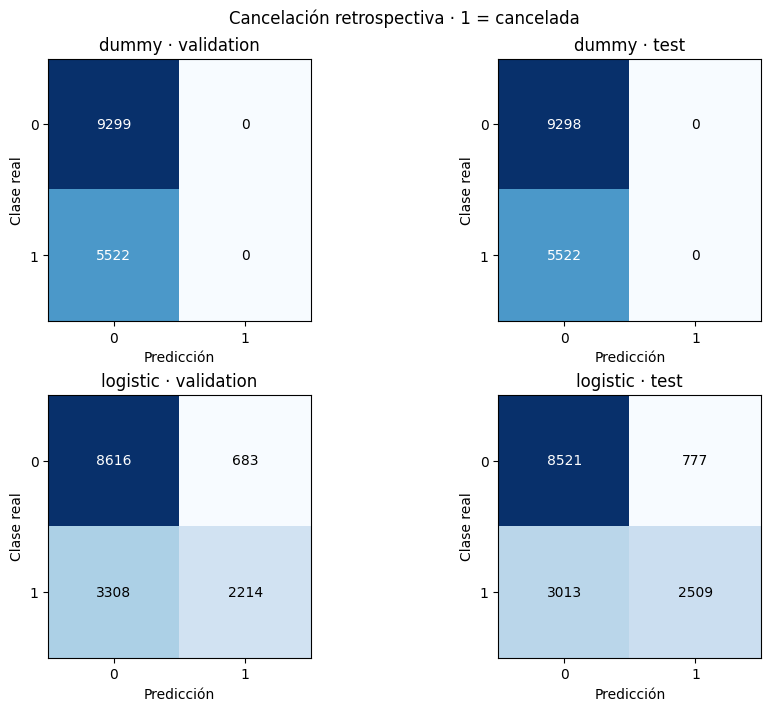

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
for row_index, model_name in enumerate(["dummy", "logistic"]):
    for column_index, split in enumerate(["validation", "test"]):
        ax = axes[row_index, column_index]
        matrix = results["classification"]["metrics"][model_name][split][
            "confusion_matrix"
        ]
        ax.imshow(matrix, cmap="Blues")
        threshold = max(max(row) for row in matrix) / 2
        for i in range(2):
            for j in range(2):
                ax.text(
                    j,
                    i,
                    str(matrix[i][j]),
                    ha="center",
                    va="center",
                    color="white" if matrix[i][j] > threshold else "black",
                )
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xlabel="Predicción",
            ylabel="Clase real",
            title=f"{model_name} · {split}",
        )
fig.suptitle("Cancelación retrospectiva · 1 = cancelada")
fig.savefig(output_dir / "confusion.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Exportaciones, manifiesto y contraste opcional

Todo lo nuevo se escribe en `outputs/notebook_phase2` (fuente, calidad, limpieza, métricas, manifiesto y matriz) y `data/processed/notebook_phase2` (cleaned y seis particiones). El CSV no se modifica. Se registran versiones, semilla, huella raw, reglas, poblaciones, predictores, estadísticas train y tamaños/histogramas de grupos.

Si existe el JSON canónico **solo se lee** para comparar; su ausencia no impide ejecutar. La referencia auditada tiene SHA-256 `99b5e3ffafbeb2540a4e6d245fc43ab33d31130cf146cbf2de1d94c40dbb0a6c`. Se comparan tareas completas (splits, métricas y diagnósticos), no se copian resultados. Puede haber redondeo entre bibliotecas/plataformas; cualquier diferencia se hace visible, no se oculta.

In [24]:
canonical_path = root / "outputs/phase2.json"
comparison = {"available": canonical_path.exists()}
if canonical_path.exists():
    reference = json.loads(canonical_path.read_text(encoding="utf-8"))
    comparison.update(
        {
            "reference_sha256": hashlib.sha256(canonical_path.read_bytes()).hexdigest(),
            "same_seed": reference["seed"] == SEED,
            "tasks_equal": {
                task: reference["tasks"][task] == results[task] for task in results
            },
            "metrics_equal": {
                task: reference["tasks"][task]["metrics"] == results[task]["metrics"]
                for task in results
            },
            "splits_equal": {
                task: reference["tasks"][task]["splits"] == results[task]["splits"]
                for task in results
            },
        }
    )
print("Contraste canónico:", comparison)
write_json(output_dir / "comparison.json", comparison)
assert (
    hashlib.sha256((raw_dir / "hotel_bookings.csv").read_bytes()).hexdigest()
    == raw_hash
)
manifest = {
    "python": sys.version.split()[0],
    "seed": SEED,
    "raw_sha256": raw_hash,
    "versions": {
        name: version(name)
        for name in [
            "polars",
            "numpy",
            "scipy",
            "scikit-learn",
            "matplotlib",
            "kagglehub",
        ]
    },
    "source": DATASET,
    "license": "CC BY 4.0",
    "original_download_date": None,
    "rules": audit["rules"],
    "input_rows": raw.height,
    "retained_rows": cleaned.height,
    "populations": {
        task: result["population_rows"] for task, result in results.items()
    },
    "artifacts": [
        "source.json",
        "quality.json",
        "cleaning.json",
        "phase2.json",
        "comparison.json",
        "outlier_profile.csv",
        "outlier_decisions.csv",
        "outlier_decisions.json",
        "adr_sensitivity_validation.csv",
        "adr_treatment_decision.json",
        "confusion.svg",
    ],
    "details": "phase2.json: splits, group histograms, X overlap, predictors, train statistics, imbalance and metrics; cleaning.json: rejected row IDs and reasons",
    "interpretation": "Retrospective snapshot day before arrival; ADR conditional on non-cancellation, not initial quote; no causality or future validation",
}
write_json(output_dir / "manifest.json", manifest)
print("Exportación terminada; original intacto.")

Contraste canónico: {'available': False}
Exportación terminada; original intacto.


## 10. Conclusiones y límites

1. La limpieza conserva una traza de cada descarte y evita eliminar automáticamente extremos legítimos. Los valores concretos se observan en las tablas ejecutadas y en `cleaning.json`.
2. Se documenta la ausencia, con incertidumbre razonable sobre MCAR/MAR/MNAR; la imputación y el escalamiento se ajustan únicamente en entrenamiento.
3. Se crean dos variables derivadas coherentes con el negocio. La partición protege huellas originales idénticas y respeta el intervalo de entrenamiento de la guía.
4. Se comparan referencias Dummy y modelos sencillos con métricas separadas para validación y prueba; **no se seleccionan tratamientos con el conjunto de prueba**.
5. Se analiza un posible tratamiento de outliers en validación sin sustituir automáticamente el baseline.
6. **Limitación central:** la clasificación es retrospectiva; los modelos no demuestran rendimiento en reservas futuras de otro periodo o establecimiento. La regresión ADR se limita a reservas no canceladas. No hay interpretación causal.

Las verificaciones automáticas de la sección 8.2 permiten comprobar las particiones y las variables derivadas. La siguiente sección empaqueta los insumos para continuar el proyecto.

## 11. Descarga de datos preparados para la Fase 3

La Fase 2 termina con una **entrega material reutilizable** para entrenar los modelos de regresión, clasificación y clustering de la Fase 3.

Se empaquetan en `Hotel_Booking_Fase2_Para_Fase3.zip` los siguientes recursos:

- **Datos limpios generales:** `cleaned.parquet` (118.564 filas con la ejecución original, sujetos a reproducirse sobre el CSV fuente). La columna `children` puede conservar nulos: **es intencional**; la imputación estadística se hace únicamente en entrenamiento.
- **Clasificación:** `classification_train.parquet`, `classification_validation.parquet`, `classification_test.parquet`; objetivo `is_canceled`.
- **Regresión:** `regression_train.parquet`, `regression_validation.parquet`, `regression_test.parquet`; objetivo `adr` y población de reservas no canceladas.
- **Clustering:** `clustering_train.parquet`, `clustering_validation.parquet`, `clustering_test.parquet`, con variables numéricas sin etiquetas de cancelación ni ADR. La partición por huella no usa la clase objetivo para estratificar.
- **Preprocesadores entrenados solo con `train`:** `classification_preprocessor.joblib`, `regression_preprocessor.joblib` y `clustering_numeric_preprocessor.joblib`. Los *holdouts* se transforman con `transform`, nunca `fit_transform`.
- **Reproducibilidad:** `README_FASE3.md`, `requirements_fase3.txt`, `manifest_fase3.json`, además de diagnósticos, sensibilidad de outliers y trazabilidad de limpieza.

**Importante:** las particiones Parquet preservan las variables originales y sus tipos para poder experimentar en la Fase 3; el encoding, la imputación estadística y el escalamiento reproducibles están en los archivos `.joblib` y **no** se han ajustado sobre validación/prueba. Los archivos Joblib solo deben abrirse si provienen de una fuente confiable. Confirme el licenciamiento y la atribución antes de redistribuir públicamente el ZIP.

La última celda crea el ZIP, valida su integridad e inicia la **descarga automática en Google Colab**. En Jupyter local mostrará la ruta del archivo creado.


In [25]:
# Paquete FINAL para la Fase 3 (sin modificar el dataset original).
# Se ajustan los preprocesadores solo con train, y se exportan junto con los splits.
from zipfile import ZIP_DEFLATED, ZipFile
import joblib

splits = ("train", "validation", "test")
model_tasks = ("classification", "regression")
expected_parquets = [processed_dir / "cleaned.parquet"] + [
    processed_dir / f"{task}_{part}.parquet"
    for task in model_tasks for part in splits
]
for file_path in expected_parquets:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Falta {file_path}. Ejecute antes las secciones de limpieza y baseline."
        )

# Clustering se particiona SIN usar la clase (classification=False).
# Se excluyen los desenlaces y las columnas de huella como predictores.
clustering_features = [
    "lead_time", "total_nights", "adults", "children", "babies",
    "previous_cancellations", "previous_bookings_not_canceled",
]
cluster_parts = split_bookings(cleaned, classification=False)
for part in splits:
    cluster_parts[part].select(
        "row_id", "original_fingerprint", *clustering_features
    ).write_parquet(processed_dir / f"clustering_{part}.parquet")
    expected_parquets.append(processed_dir / f"clustering_{part}.parquet")

cluster_fingerprints = {
    part: set(cluster_parts[part]["original_fingerprint"]) for part in splits
}
assert all(
    not (cluster_fingerprints[a] & cluster_fingerprints[b])
    for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]
), "Solapamiento de huellas en clustering"
assert sum(cluster_parts[part].height for part in splits) == cleaned.height

preprocessor_dir = output_dir / "preprocessors"
preprocessor_dir.mkdir(parents=True, exist_ok=True)
preprocessor_paths = []

# Ajuste independiente para cada tarea; solo observa X_train y conserva columnas de entrada.
for task in model_tasks:
    numeric, categorical = feature_columns(task)
    train_data = pl.read_parquet(processed_dir / f"{task}_train.parquet")
    train_features = train_data.select(numeric + categorical).with_columns([
        pl.col(name).cast(pl.String).fill_null("__MISSING__")
        for name in categorical
    ])
    preprocessor = make_preprocessor(numeric, categorical)
    preprocessor.fit(train_features)
    # Verificación de procedencia de medianas: train y nada más.
    expected_medians = np.array([
        float(train_data[name].drop_nulls().median()) for name in numeric
    ])
    fitted_medians = preprocessor.named_transformers_["numeric"].named_steps[
        "imputer"
    ].statistics_
    assert np.allclose(fitted_medians, expected_medians, equal_nan=True)
    path = preprocessor_dir / f"{task}_preprocessor.joblib"
    joblib.dump(preprocessor, path, compress=3)
    preprocessor_paths.append(path)

# Solo variables cuantitativas en clustering; escalar todo el dataset filtraría
# información de validación/prueba a través de medias y desviaciones globales.
cluster_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scale", StandardScaler()),
])
cluster_train = pl.read_parquet(processed_dir / "clustering_train.parquet")
cluster_preprocessor.fit(cluster_train.select(clustering_features).to_numpy())
assert np.allclose(
    cluster_preprocessor.named_steps["imputer"].statistics_,
    np.array([float(cluster_train[c].drop_nulls().median()) for c in clustering_features]),
    equal_nan=True,
)
cluster_preprocessor_path = preprocessor_dir / "clustering_numeric_preprocessor.joblib"
joblib.dump(cluster_preprocessor, cluster_preprocessor_path, compress=3)
preprocessor_paths.append(cluster_preprocessor_path)

requirements_path = output_dir / "requirements_fase3.txt"
requirements_path.write_text(
    "".join(
        f"{package}=={version(package)}\n"
        for package in ["polars", "numpy", "scipy", "scikit-learn", "joblib"]
    ),
    encoding="utf-8",
)
readme_path = output_dir / "README_FASE3.md"
readme_path.write_text(
    """# Entrega Fase 2 → Fase 3 | Hotel Booking Demand

Archivos creados por el notebook de Fase 2. Se conserva el CSV fuente original intacto.

## Organización
- `data/processed/cleaned.parquet`: limpieza común con variables derivadas y trazas.
- `data/processed/classification_{train,validation,test}.parquet`: X e `is_canceled`.
- `data/processed/regression_{train,validation,test}.parquet`: X y `adr`, no canceladas.
- `data/processed/clustering_{train,validation,test}.parquet`: numéricas sin objetivos.
- `preprocessors/*.joblib`: transformaciones ajustadas solo sobre train.
- `audit/`: diagnósticos y resultados de la Fase 2.

## Cargar sin fuga de información (Python)

```python
from pathlib import Path
import polars as pl
import joblib

base = Path('data/processed')
train = pl.read_parquet(base / 'classification_train.parquet')
val = pl.read_parquet(base / 'classification_validation.parquet')
pre = joblib.load('preprocessors/classification_preprocessor.joblib')  # Solo archivos propios
numeric = ['lead_time', 'adults', 'children', 'babies', 'total_nights',
           'previous_cancellations', 'previous_bookings_not_canceled']
categorical = ['hotel', 'arrival_date_month', 'meal', 'market_segment',
               'distribution_channel', 'is_repeated_guest',
               'reserved_room_type', 'customer_type']
def X(df):
    return df.select(numeric + categorical).with_columns([
        pl.col(c).cast(pl.String).fill_null('__MISSING__') for c in categorical
    ])
X_train = pre.transform(X(train))   # No pre.fit() sobre test/validación
X_val = pre.transform(X(val))
y_train = train['is_canceled'].to_numpy()
y_val = val['is_canceled'].to_numpy()
```

Para regresión, sustituya `classification` por `regression` y use objetivo `adr`.
Para clustering, aplique el `clustering_numeric_preprocessor.joblib` sobre las
columnas numéricas de `clustering_train.parquet` con `transform`; no debe
introducir `is_canceled` ni `adr` como predictores.

Los `.parquet` contienen `row_id` y `original_fingerprint` para auditoría:
NO usarlos como predictores. `total_guests` puede conservar valores nulos por
definición y no forma parte de X de los baselines. Los archivos Parquet NO están
preescalados globalmente de forma deliberada (evita data leakage).

Ver `audit/adr_treatment_decision.json` y `audit/outlier_decisions.csv` para la
justificación de la conservación de extremos plausibles. Las pérdidas por
valores inválidos están registradas en `audit/cleaning.json`.

IMPORTANTE: compruebe la licencia/atribución antes de publicar los datos.
""",
    encoding="utf-8",
)

# Inventario de archivos, conteos y sumas de verificación sin incluir el manifiesto
# dentro de su propio inventario (evita dependencia circular).
audit_names = [
    "source.json", "quality.json", "cleaning.json", "phase2.json", "manifest.json",
    "outlier_profile.csv", "outlier_decisions.csv", "outlier_decisions.json",
    "adr_sensitivity_validation.csv", "adr_treatment_decision.json",
]
audit_files = [output_dir / name for name in audit_names]
missing_audits = [str(f) for f in audit_files if not f.is_file()]
if missing_audits:
    raise FileNotFoundError(f"Debe ejecutar todas las celdas antes de exportar: {missing_audits}")
files_to_package = (
    [(p, f"data/processed/{p.name}") for p in expected_parquets]
    + [(p, f"preprocessors/{p.name}") for p in preprocessor_paths]
    + [(p, f"audit/{p.name}") for p in audit_files]
    + [(requirements_path, requirements_path.name), (readme_path, readme_path.name)]
)
assert len(set(arc for _, arc in files_to_package)) == len(files_to_package)
manifest_phase3 = {
    "description": "Fase 2 lista para modelado; datos no preescalados globalmente",
    "source": DATASET,
    "raw_sha256": raw_hash,
    "seed": SEED,
    "train_only_preprocessing": True,
    "clustering_features": clustering_features,
    "splits": {
        "classification": {p: results["classification"]["splits"][p]["rows"] for p in splits},
        "regression": {p: results["regression"]["splits"][p]["rows"] for p in splits},
        "clustering": {p: cluster_parts[p].height for p in splits},
    },
    "files": [
        {
            "path": arcname,
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
        for path, arcname in files_to_package
    ],
    "notes": (
        "No fit on validation/test. Parquet splits preserve non-imputed missing "
        "numeric values; use the matching fitted joblib preprocessor for transform. "
        "Do not use row_id/fingerprint as predictors. Reconfirm redistribution license."
    ),
}
manifest_path = output_dir / "manifest_fase3.json"
write_json(manifest_path, manifest_phase3)
files_to_package.append((manifest_path, "manifest_fase3.json"))

zip_path = root / "Hotel_Booking_Fase2_Para_Fase3.zip"
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED, compresslevel=6) as archive:
    for file_path, archive_name in files_to_package:
        archive.write(file_path, arcname=archive_name)
with ZipFile(zip_path) as archive:
    assert archive.testzip() is None, "Se encontró un archivo dañado dentro del ZIP"
    assert len(archive.namelist()) == len(files_to_package)
print(f"ZIP creado y validado: {zip_path}")
print(f"Tamaño: {zip_path.stat().st_size / 1024**2:.2f} MiB")
print(f"Archivos incluidos: {len(files_to_package)}")
print("Reservas en clasificación y clustering:", sum(cluster_parts[s].height for s in splits))
print("Entrenamiento / validación / prueba separados y con preprocesadores de train.")

# El navegador iniciará la descarga tras ejecutar esta celda en Google Colab.
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(zip_path))
else:
    print("Ejecución local: descargue/copie manualmente el ZIP desde la ruta anterior.")


ZIP creado y validado: /content/Hotel_Booking_Fase2_Para_Fase3.zip
Tamaño: 6.06 MiB
Archivos incluidos: 26
Reservas en clasificación y clustering: 118564
Entrenamiento / validación / prueba separados y con preprocesadores de train.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>